# Eksperimen 03 (Frankenstein Meta-Ensemble): Cetak Biru Operasional

Dokumen ini adalah panduan teknis (*Standard Operating Procedure*) mutlak untuk mengeksekusi Eksperimen 03. Tujuan utama kita adalah mencapai **Skor MASE < 0.3** dengan menggabungkan peretasan matematis (skala $S_p$), keamanan validasi (`GroupKFold`), arsitektur multi-model (*Stacking Ensemble*), dan pemrosesan bahasa alami (NLP).

## Penjabaran Taktis per Fase (Milestone M1 - M10)

### M1: Setup & Environment Initialization
- **Tujuan:** Mengunci *seed* rawak (42) untuk reproduktibilitas 100% dan memuat seluruh *library* tingkat lanjut.
- **Teknologi:** `lightgbm`, `catboost`, `xgboost`, `sentence_transformers` (untuk NLP Embeddings), `optuna`, `scikit-learn` (Ridge/Lasso untuk meta-learner).

### M2: Data Extraction & Mathematical Preprocessing (Krusial)
- **Ekstraksi Sejarah (D1-D3):** Mengekstrak data awal untuk `train.csv` (dari dirinya sendiri) dan `test.csv` (dari `test_history.csv`) menggunakan *groupby* kombinasi mutlak `['movie_title', 'cinema_ids']`.
- **Peretasan MASE (S_p Scaling):** Menghitung batas bawah MASE, $S_p = max(mean(D1..D3), 1.0)$.
- **Skala Target (Rahasia Skor 0.3):** Mengubah target utama pelatihan dari `total_ticket` menjadi `y_scaled = total_ticket / Sp`. Seluruh algoritma (LGBM, CatBoost, XGBoost) nantinya akan dilatih dengan target ini menggunakan *loss function* MAE (L1 Loss).

### M3: Feature Engineering (Dinamika Kurva & Waktu)
- **Rasio Momentum Eksponensial:** Menghitung peluruhan non-linier seperti `ratio_d3_d1 = (ticket_d3 + 1) / (ticket_d1 + 1)` dan `momentum_d3_d2 = (ticket_d3 - ticket_d2) / (ticket_d2 + 1)`.
- **Fitur Kalender Kompleks:** Mengekstrak *day_number* (D4 = 3, dst), status *weekend*, hari libur, dan estimasi potensi pendapatan (`total_show * price`).
- **Penyatuan Dataset:** Menggabungkan seluruh data tabular (`movies.csv`, `holidays.csv`, `ticket_prices.csv`) dengan sangat aman.

### M4: Categorical Handling & NLP Embeddings (Revolusi)
- **TIDAK ADA PENGHAPUSAN KOLOM TEKS.** Kita melarang keras penghapusan `movie_title` dan `director`.
- **NLP Embeddings (Untuk Meta-Model/XGB/LGB):** Menggunakan `SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')` untuk mengubah `movie_title` dan `genre` menjadi vektor representasi semantik. Vektor ini di-*reduksi* dimensinya dengan PCA (misal: 5-10 dimensi) agar bisa dicerna pohon keputusan.
- **Native Categorical (Untuk CatBoost):** *CatBoost* secara alamiah akan mencerna fitur kategori teks mentah.

### M5: Feature Selection
- Mengamankan daftar akhir dari **Fitur Prediktor (`FEATURES`)**.
- Memastikan **Paritas Kolom 100%** antara *Training Set* dan *Testing Set*. Jika ada yang hilang di *Test*, otomatis diselaraskan atau direkonstruksi.

### M6: Hyperparameter Tuning (Optuna Ekstrem)
- Kita tidak menebak parameter. Kita akan menjalankan dua blok Optuna secara terpisah (satu untuk LightGBM, satu untuk XGBoost/CatBoost).
- **Fungsi Objektif Optuna:** Secarah harfiah meminimalkan validasi L1 pada target terskala (`y_scaled`) menggunakan `GroupKFold(groups=movie_title)`.

### M7: Cross-Validation & Stacking Ensemble (Inti Otak)
- Menggunakan `GroupKFold(n_splits=5)`.
- **Lapis 1 (Base Learners):** Melatih 3 model (LightGBM, CatBoost, XGBoost) pada setiap lipatan (*fold*). Kita akan menyimpan prediksi *Out-of-Fold* (OOF) mereka ke dalam matriks baru.
- **Lapis 2 (Meta-Learner):** Menggunakan model linier kuat seperti `RidgeCV` atau `LinearRegression` untuk mempelajari matriks prediksi Lapis 1. *Ridge* akan otomatis membebani (memberikan bobot probabilitas) ke model yang paling akurat, misal: *0.55 LGB + 0.35 CAT + 0.10 XGB*.

### M8: Evaluasi Kritis
- Mengubah kembali `y_scaled` hasil meta-learner menjadi satuan tiket asli ($y = y\_scaled \times S_p$).
- Menghitung MASE akhir. Kita menargetkan **CV Lokal < 0.40**.
- Melakukan analisis *Feature Importance* (terutama mengecek apakah NLP Embeddings benar-benar terpakai).

### M9: Inferensi (Data Uji Tertutup)
- Menerapkan *Pipeline* M2 hingga M4 yang **100% identik** kepada data `test.csv`. Menjamin ekstraksi NLP dan kalkulasi $S_p$ berjalan tanpa cacat.
- Melakukan inferensi Lapis 1 pada *test*, lalu diumpankan ke Lapis 2 (*Meta-Learner*).
- Memotong (*clipping*) prediksi agar tidak menghasilkan tiket bernilai negatif.

### M10: Submission Generation
- Membentuk *DataFrame* berisi `id` dan `total_ticket`.
- Mengamankan berkas final ke dalam `submission_exp03.csv`. Menutup dengan pencetakan 10 baris pertama untuk inspeksi visual.


# Eksperimen 03: Frankenstein Meta-Ensemble (Target MASE < 0.3)

Ini adalah implementasi pamungkas berdasarkan *blueprint* rahasia **exp03_analytic.md**. Di sini kita mengawinkan teknik peretasan skala $S_p$, arsitektur multi-model (*Stacking* LightGBM + CatBoost + XGBoost), dan sistem ekstraksi bahasa alami (NLP Embeddings) untuk mempertahankan konteks kardinalitas secara sempurna.

---
## 1. M1: Setup & Import Library
Menginisiasi *environment* tingkat dewa dan mengunci *seed*.

In [6]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Core
import lightgbm as lgb
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import RidgeCV

# Validation & Metrics
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error

# NLP Embeddings (Opsional)
try:
    from sentence_transformers import SentenceTransformer
    from sklearn.decomposition import PCA
    NLP_READY = True
    print("Hore! Pustaka NLP 'sentence_transformers' tersedia.")
except ImportError:
    NLP_READY = False
    print("Peringatan: 'sentence_transformers' tidak terinstal. Kita mungkin harus beralih ke Target Encoding murni.")

# Optuna
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)

# Seed Lock
SEED = 42
np.random.seed(SEED)
print(f"\n>>> Environment Siap! SEED = {SEED} <<<")

Hore! Pustaka NLP 'sentence_transformers' tersedia.

>>> Environment Siap! SEED = 42 <<<


## 2. M2: Data Extraction & Mathematical Preprocessing (Sp Scaling)

Di fase kritis ini, kita akan membongkar seluruh dataset (Data Ingestion) dan langsung mengekstrak metrik profil **D1-D3** serta menghitung variabel `Sp` (pembagi untuk MASE) pada `train` maupun `test_history`.

In [7]:
# A. Data Ingestion
possible_paths = ['../../../dataset', '../../dataset', '../dataset']
data_dir = None
for p in possible_paths:
    if os.path.exists(os.path.join(p, 'train.csv')):
        data_dir = p
        break

if data_dir is None:
    raise FileNotFoundError('Direktori dataset tidak ditemukan!')

print(f'>> Memuat data dari direktori: {data_dir}')
train = pd.read_csv(os.path.join(data_dir, 'train.csv'))
test = pd.read_csv(os.path.join(data_dir, 'test.csv'))
test_history = pd.read_csv(os.path.join(data_dir, 'test_history.csv'))
movies = pd.read_csv(os.path.join(data_dir, 'movies.csv'))
holidays = pd.read_csv(os.path.join(data_dir, 'holidays.csv'))
ticket_prices = pd.read_csv(os.path.join(data_dir, 'ticket_prices.csv'))

# Parsing Datetime
train['date_show'] = pd.to_datetime(train['date_show'])
test['date_show'] = pd.to_datetime(test['date_show'])
test_history['date_show'] = pd.to_datetime(test_history['date_show'])
holidays['date'] = pd.to_datetime(holidays['date'])

print(f'Train shape        : {train.shape}')
print(f'Test shape         : {test.shape}')
print(f'Test History shape : {test_history.shape}')

# B. Arsitektur Ekstraksi Profil Sejarah D1-D3 & Sp Scaling
def extract_d1_d3_profile(df_hist):
    df_hist = df_hist.sort_values(['movie_title', 'cinema_ids', 'date_show']).copy()
    first_dates = df_hist.groupby(['movie_title', 'cinema_ids'])['date_show'].transform('min')
    df_hist['day_since_release'] = (df_hist['date_show'] - first_dates).dt.days
    d1_d3_subset = df_hist[df_hist['day_since_release'].isin([0, 1, 2])].copy()
    
    # Agregasi Statistik Historis
    prof = d1_d3_subset.groupby(['movie_title', 'cinema_ids']).agg(
        d1_d3_mean=('total_ticket', 'mean'),
        d1_d3_max=('total_ticket', 'max'),
        d1_d3_min=('total_ticket', 'min'),
        d1_d3_sum=('total_ticket', 'sum'),
        d1_d3_std=('total_ticket', 'std'),
        d1_d3_show_mean=('total_show', 'mean'),
        d1_d3_show_max=('total_show', 'max'),
        d1_d3_show_sum=('total_show', 'sum'),
        d1_d3_occ_mean=('occupation_rate', 'mean'),
        d1_d3_occ_max=('occupation_rate', 'max'),
        d1_d3_occ_std=('occupation_rate', 'std')
    ).reset_index()
    
    # Skala MASE Sp = clip(mean(D1..D3), lower=1.0)
    prof['Sp'] = prof['d1_d3_mean'].clip(lower=1.0)
    prof['d1_d3_std'] = prof['d1_d3_std'].fillna(0)
    prof['d1_d3_occ_std'] = prof['d1_d3_occ_std'].fillna(0)
    
    # Pivot Tiket Harian D1, D2, D3
    piv_ticket = d1_d3_subset.pivot_table(index=['movie_title', 'cinema_ids'], columns='day_since_release', values='total_ticket', fill_value=0).reset_index()
    piv_ticket.columns = ['movie_title', 'cinema_ids'] + [f'ticket_d{int(c)+1}' for c in piv_ticket.columns[2:]]
    prof = prof.merge(piv_ticket, on=['movie_title', 'cinema_ids'], how='left')
    
    # Imputasi jika hari tertentu bolong
    for col in ['ticket_d1', 'ticket_d2', 'ticket_d3']:
        if col not in prof.columns:
            prof[col] = prof['d1_d3_mean']
        else:
            prof[col] = prof[col].fillna(prof['d1_d3_mean'])
            
    # Dinamika Peluruhan Intrinsik (Momentum & Efisiensi Layar)
    prof['d1_d3_trend'] = prof['ticket_d3'] - prof['ticket_d1']
    prof['ratio_d2_d1'] = (prof['ticket_d2'] + 1) / (prof['ticket_d1'] + 1)
    prof['ratio_d3_d2'] = (prof['ticket_d3'] + 1) / (prof['ticket_d2'] + 1)
    prof['ratio_d3_d1'] = (prof['ticket_d3'] + 1) / (prof['ticket_d1'] + 1)
    prof['d1_d3_ticket_per_show'] = (prof['d1_d3_sum'] + 1) / (prof['d1_d3_show_sum'] + 1)
    
    # Tanggal rilis pertama (Anchor Date)
    rel_dates = d1_d3_subset.groupby(['movie_title', 'cinema_ids'])['date_show'].min().reset_index(name='release_date')
    prof = prof.merge(rel_dates, on=['movie_title', 'cinema_ids'], how='left')
    
    return prof

print('\nMengeksekusi Mesin Profiling M2...')
train_d1_d3 = extract_d1_d3_profile(train)
test_d1_d3 = extract_d1_d3_profile(test_history)

print(f'✅ Profil D1-D3 Train berhasil dibentuk: {train_d1_d3.shape}')
print(f'✅ Profil D1-D3 Test berhasil dibentuk : {test_d1_d3.shape}')


>> Memuat data dari direktori: ../../dataset
Train shape        : (138959, 7)
Test shape         : (72611, 5)
Test History shape : (32323, 7)

Mengeksekusi Mesin Profiling M2...
✅ Profil D1-D3 Train berhasil dibentuk: (13041, 23)
✅ Profil D1-D3 Test berhasil dibentuk : (11823, 23)


## 3. M3: Feature Engineering & Penyatuan Dataset (Data Fusion)

Tahap Alkimia: Kita menggabungkan matriks target (D4-D10) dengan profil M2, menyuntikkan data liburan, mensimulasikan kurva peluruhan (*expected decay*), dan mengubah target ke `y_scaled`.

In [8]:
def build_features(df_target, prof_d1_d3, is_train=True):
    df = df_target.copy()
    
    # 1. Fusi D1-D3 Profile
    df = df.merge(prof_d1_d3, on=['movie_title', 'cinema_ids'], how='left')
    
    # 2. Perhitungan Hari Sejak Rilis
    df['day_since_release'] = (df['date_show'] - df['release_date']).dt.days
    
    # Isolasi Dimensi Latih (Hanya D4-D10)
    if is_train:
        df = df[df['day_since_release'].isin([3, 4, 5, 6, 7, 8, 9])].copy()
        
    # 3. Injeksi Data Eksternal (Metadata Film)
    df = df.merge(movies[['original_title', 'age_rating', 'genre', 'director']], left_on='movie_title', right_on='original_title', how='left')
    df['age_rating'] = df['age_rating'].fillna('Unknown')
    df['genre'] = df['genre'].fillna('Unknown')
    df['director'] = df['director'].fillna('Unknown')
    
    # 4. Konteks Waktu & Kalender
    df['day_of_week'] = df['date_show'].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([4, 5, 6]).astype(int)  # Jumat, Sabtu, Minggu
    df['is_sat_sun'] = df['day_of_week'].isin([5, 6]).astype(int)
    df['is_friday'] = (df['day_of_week'] == 4).astype(int)
    df['day_of_month'] = df['date_show'].dt.day
    df['month'] = df['date_show'].dt.month
    df['is_month_end'] = df['date_show'].dt.is_month_end.astype(int)
    
    # Injeksi Liburan (Holidays)
    df = df.merge(holidays[['date', 'day_tipe', 'holiday_tipe']], left_on='date_show', right_on='date', how='left')
    df['is_holiday'] = (df['holiday_tipe'] == 'holiday').astype(int)
    df['is_holiday_weekend'] = df['is_weekend'] * df['is_holiday']
    
    # 5. Konteks Ekonomi (Ticket Prices)
    df['extracted_day_tipe'] = np.where(df['day_of_week'] < 4, 'Weekday', np.where(df['day_of_week'] == 4, 'Friday', 'Weekend'))
    df = df.merge(ticket_prices, left_on=['city_name', 'extracted_day_tipe'], right_on=['city_name', 'price_day'], how='left')
    df['price_ceil'] = df['ceil'].fillna(35000)
    df['potential_revenue_est'] = df['price_ceil'] * df['d1_d3_show_mean']
    
    # 6. Dinamika Kurva Eksponensial (Rumus Fisika)
    df['expected_decay'] = 1.0 / (1.0 + 0.15 * (df['day_since_release'] - 2))
    df['decay_sp_interaction'] = df['Sp'] * df['expected_decay']
    df['weekend_sp_interaction'] = df['Sp'] * (1.0 + 0.5 * df['is_weekend']) # Lonjakan asimtot akhir pekan
    df['day_num'] = df['day_since_release'] + 1
    
    # 7. Pembersihan & Konversi Kategorikal
    drop_cols = ['date_show', 'date', 'price_day', 'extracted_day_tipe', 'original_title', 'release_date', 'day_tipe', 'holiday_tipe', 'ceil']
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True, errors='ignore')
    
    cat_cols = ['cinema_ids', 'city_name', 'movie_title', 'age_rating', 'genre', 'director']
    for c in cat_cols:
        df[c] = df[c].astype('category')
        
    return df, cat_cols

print('>> Merakit Fitur (Feature Engineering M3)...')
df_train, cat_cols = build_features(train, train_d1_d3, is_train=True)
df_test, _ = build_features(test, test_d1_d3, is_train=False)

# 8. Peretasan MASE (Konversi Target L1)
df_train['y_scaled'] = df_train['total_ticket'] / df_train['Sp']

# Mendefinisikan kolom prediktor final
feature_cols = [c for c in df_train.columns if c not in ['total_ticket', 'occupation_rate', 'total_show', 'y_scaled']]

print(f'✅ Matriks Train Siap : {df_train.shape}')
print(f'✅ Matriks Test Siap  : {df_test.shape}')
print(f'✅ Jumlah Fitur (Predictors) : {len(feature_cols)}')
print('\nFitur Kategori:', cat_cols)


>> Merakit Fitur (Feature Engineering M3)...
✅ Matriks Train Siap : (48351, 46)
✅ Matriks Test Siap  : (72611, 43)
✅ Jumlah Fitur (Predictors) : 42

Fitur Kategori: ['cinema_ids', 'city_name', 'movie_title', 'age_rating', 'genre', 'director']


## 4. M4: Categorical Handling & NLP Embeddings

Kita menolak menghapus kolom kardinalitas tinggi seperti `movie_title` atau `director`! Di fase ini kita mengubah genre dan nama film menjadi 384 dimensi probabilitas makna dengan NLP (*SentenceTransformers*), lalu memadatkannya menjadi 5 fitur utama (*PCA*) agar bisa dihisap dengan rakus namun ringan oleh *Decision Tree*.

In [9]:
print('>> Memulai Ekstraksi Semantik NLP...')
if NLP_READY:
    # 1. Merakit Korpus Teks dari movies.csv
    movies_nlp = movies[['original_title', 'genre', 'director']].copy()
    movies_nlp['nlp_text'] = movies_nlp['genre'] + " - " + movies_nlp['original_title'] + " (Sutradara: " + movies_nlp['director'] + ")"
    
    unique_texts = movies_nlp['nlp_text'].unique()
    print(f'Mengeksekusi Model SentenceTransformer pada {len(unique_texts)} judul unik...')
    
    # 2. Vektorisasi Teks (Membuat 384 Dimensi Makna)
    model_nlp = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
    embeddings = model_nlp.encode(unique_texts, show_progress_bar=False)
    
    # 3. Kompresi Dimensi dengan PCA
    print('Mengompresi 384 Dimensi menjadi 5 Dimensi Utama menggunakan PCA...')
    pca = PCA(n_components=5, random_state=SEED)
    pca_embeddings = pca.fit_transform(embeddings)
    
    # Petakan kembali ke dictionary
    emb_dict = {text: pca_embeddings[i] for i, text in enumerate(unique_texts)}
    
    pca_cols = [f'nlp_pca_{i}' for i in range(5)]
    movies_nlp[pca_cols] = pd.DataFrame(movies_nlp['nlp_text'].map(emb_dict).tolist(), index=movies_nlp.index)
    
    # 4. Injeksi ke Matriks Train & Test
    df_train = df_train.merge(movies_nlp[['original_title'] + pca_cols], left_on='movie_title', right_on='original_title', how='left').drop(columns=['original_title'])
    df_test = df_test.merge(movies_nlp[['original_title'] + pca_cols], left_on='movie_title', right_on='original_title', how='left').drop(columns=['original_title'])
    
    feature_cols.extend(pca_cols)
    print(f'✅ Ekstraksi NLP Sukses! 5 Fitur Makna berhasil ditambahkan.')
else:
    print('Peringatan: NLP Embeddings dilewati karena library tidak tersedia.')

print(f'\n[FINAL M4] Daftar {len(feature_cols)} Fitur Prediktor yang siap masuk arena ML:')
print(feature_cols)


>> Memulai Ekstraksi Semantik NLP...
Mengeksekusi Model SentenceTransformer pada 397 judul unik...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Mengompresi 384 Dimensi menjadi 5 Dimensi Utama menggunakan PCA...
✅ Ekstraksi NLP Sukses! 5 Fitur Makna berhasil ditambahkan.

[FINAL M4] Daftar 47 Fitur Prediktor yang siap masuk arena ML:
['cinema_ids', 'city_name', 'movie_title', 'd1_d3_mean', 'd1_d3_max', 'd1_d3_min', 'd1_d3_sum', 'd1_d3_std', 'd1_d3_show_mean', 'd1_d3_show_max', 'd1_d3_show_sum', 'd1_d3_occ_mean', 'd1_d3_occ_max', 'd1_d3_occ_std', 'Sp', 'ticket_d1', 'ticket_d2', 'ticket_d3', 'd1_d3_trend', 'ratio_d2_d1', 'ratio_d3_d2', 'ratio_d3_d1', 'd1_d3_ticket_per_show', 'day_since_release', 'age_rating', 'genre', 'director', 'day_of_week', 'is_weekend', 'is_sat_sun', 'is_friday', 'day_of_month', 'month', 'is_month_end', 'is_holiday', 'is_holiday_weekend', 'price_ceil', 'potential_revenue_est', 'expected_decay', 'decay_sp_interaction', 'weekend_sp_interaction', 'day_num', 'nlp_pca_0', 'nlp_pca_1', 'nlp_pca_2', 'nlp_pca_3', 'nlp_pca_4']


## 5. M5: Feature Selection & Parity Validation

Tahap sterilisasi matriks: Memastikan 100% kesamaan pilar kolom antara `train` dan `test`, memisahkan matriks `X` dan `y_scaled`, serta menegakkan aturan tipe data agar algoritma tidak mengalami malfungsi.

In [10]:
print('>> Melakukan Seleksi Fitur & Uji Paritas (M5)...')

# A. Pendefinisian Target
TARGET_TRAIN = 'y_scaled'
TARGET_EVAL = 'total_ticket'

# B. Keamanan Tipe Data & Missing Values
for c in feature_cols:
    if c in cat_cols:
        df_train[c] = df_train[c].astype('category')
        df_test[c] = df_test[c].astype('category')
    else:
        # Isi NaN pada numerik agar XGBoost lebih stabil
        df_train[c] = df_train[c].fillna(-1)
        df_test[c] = df_test[c].fillna(-1)

# C. Uji Paritas Ekstrem
missing_in_train = set(feature_cols) - set(df_train.columns)
missing_in_test = set(feature_cols) - set(df_test.columns)

if missing_in_train:
    raise ValueError(f"FATAL: Fitur {missing_in_train} hilang di Data Latih!")
if missing_in_test:
    raise ValueError(f"FATAL: Fitur {missing_in_test} hilang di Data Uji!")

print('✅ Uji Paritas Sukses! df_train dan df_test memiliki pilar fitur yang identik.')

# Memisahkan Matriks (X dan y)
X_train = df_train[feature_cols].copy()
y_train_scaled = df_train[TARGET_TRAIN].copy()
y_train_raw = df_train[TARGET_EVAL].copy()
sp_train = df_train['Sp'].copy()
group_train = df_train['movie_title'].copy()

X_test = df_test[feature_cols].copy()
sp_test = df_test['Sp'].copy()

print(f'Dimensi Pelatihan X_train : {X_train.shape}')
print(f'Dimensi Pengujian X_test  : {X_test.shape}')


>> Melakukan Seleksi Fitur & Uji Paritas (M5)...
✅ Uji Paritas Sukses! df_train dan df_test memiliki pilar fitur yang identik.
Dimensi Pelatihan X_train : (48351, 47)
Dimensi Pengujian X_test  : (72611, 47)


## 6. M6: Hyperparameter Tuning Optuna (GroupKFold)

Arena gladiator: Mencari parameter terkuat (*Best Params*) untuk **LightGBM** dan **CatBoost** menggunakan 15 iterasi cerdas (*Tree-structured Parzen Estimator*). Kita memvalidasi performanya murni pada judul film yang belum pernah dilihat (*GroupKFold*) menggunakan target terskala `y_scaled`.

In [11]:
print('>> Mengaktifkan Mesin Optuna (M6)...')

# Parameter Pengendalian Optuna (dibatasi agar tidak terlalu lama di Jupyter)
N_TRIALS = 15 
N_SPLITS = 3

# Fungsi Bantuan Evaluasi CV (Dynamic Early Stopping)
def evaluate_model_cv(model, X, y, groups):
    gkf = GroupKFold(n_splits=N_SPLITS)
    cv_scores = []
    
    for train_idx, val_idx in gkf.split(X, y, groups):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
        
        # Fit with early stopping dynamically
        if isinstance(model, lgb.LGBMRegressor):
            model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(30, verbose=False)])
        elif isinstance(model, CatBoostRegressor):
            model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], early_stopping_rounds=30, verbose=False)
        else:
            model.fit(X_tr, y_tr)
            
        preds = model.predict(X_va)
        score = mean_absolute_error(y_va, preds)
        cv_scores.append(score)
        
    return np.mean(cv_scores)

# --- Arena 1: LightGBM ---
def objective_lgbm(trial):
    params = {
        'objective': 'regression_l1',
        'metric': 'mae',
        'boosting_type': 'gbdt',
        'random_state': SEED,
        'n_estimators': 800,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 100),
        'max_depth': trial.suggest_int('max_depth', 5, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'verbose': -1
    }
    model = lgb.LGBMRegressor(**params)
    return evaluate_model_cv(model, X_train, y_train_scaled, group_train)

# --- Arena 2: CatBoost ---
def objective_catboost(trial):
    params = {
        'loss_function': 'MAE',
        'eval_metric': 'MAE',
        'random_seed': SEED,
        'iterations': 800,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'random_strength': trial.suggest_float('random_strength', 0.1, 5.0),
        'cat_features': cat_cols
    }
    model = CatBoostRegressor(**params)
    return evaluate_model_cv(model, X_train, y_train_scaled, group_train)

# Eksekusi Ekstrem Optuna
print('Memulai Tuning LightGBM (15 Trials)...')
study_lgbm = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_lgbm.optimize(objective_lgbm, n_trials=N_TRIALS)

print('\nMemulai Tuning CatBoost (15 Trials)...')
study_cat = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
study_cat.optimize(objective_catboost, n_trials=N_TRIALS)

# Menyimpan Parameter Terbaik
BEST_LGBM_PARAMS = study_lgbm.best_params
BEST_CAT_PARAMS = study_cat.best_params

# Tambahkan parameter statis yang tidak di-tune
BEST_LGBM_PARAMS.update({'objective': 'regression_l1', 'metric': 'mae', 'n_estimators': 800, 'random_state': SEED, 'verbose': -1})
BEST_CAT_PARAMS.update({'loss_function': 'MAE', 'eval_metric': 'MAE', 'iterations': 800, 'random_seed': SEED, 'cat_features': cat_cols})

print(f'\n🏆 [LightGBM] Best L1 Score (y_scaled): {study_lgbm.best_value:.5f}')
print(f'🏆 [CatBoost] Best L1 Score (y_scaled): {study_cat.best_value:.5f}')
print('\nTuning Selesai! Parameter Sakti diamankan untuk M7.')


>> Mengaktifkan Mesin Optuna (M6)...
Memulai Tuning LightGBM (15 Trials)...

Memulai Tuning CatBoost (15 Trials)...

🏆 [LightGBM] Best L1 Score (y_scaled): 0.57045
🏆 [CatBoost] Best L1 Score (y_scaled): 0.56847

Tuning Selesai! Parameter Sakti diamankan untuk M7.


## 7. M7: Cross-Validation & Meta-Ensemble Stacking

Tahap pertempuran absolut. Tiga algoritma raksasa (LightGBM, CatBoost, XGBoost) akan saling adu akurasi di dalam 5 siklus lipatan (*GroupKFold*). Seluruh tebakan *Out-of-Fold* mereka kemudian diserahkan kepada Mahkamah Meta-Learner (`RidgeCV`) untuk digabungkan menjadi satu skor prediksi *y_scaled* pamungkas.

In [13]:
print('>> Memulai Pertempuran Inti: Cross-Validation & Stacking (M7)...')

# A. Fallback Protocol (Keamanan Run-This-Cell)
try:
    BEST_LGBM_PARAMS
except NameError:
    print("[WARNING] BEST_LGBM_PARAMS tidak ditemukan. Memuat Fallback Parameter Sakti...")
    BEST_LGBM_PARAMS = {
        'objective': 'regression_l1', 'metric': 'mae', 'n_estimators': 1500, 'random_state': 42, 'verbose': -1,
        'learning_rate': 0.05, 'num_leaves': 45, 'max_depth': 8, 'min_child_samples': 25, 'subsample': 0.8, 'colsample_bytree': 0.8
    }
    BEST_CAT_PARAMS = {
        'loss_function': 'MAE', 'eval_metric': 'MAE', 'iterations': 1500, 'random_seed': 42, 'cat_features': cat_cols,
        'learning_rate': 0.05, 'depth': 6, 'l2_leaf_reg': 3.0, 'random_strength': 1.0
    }

# B. Penyiapan Gudang OOF (Out-of-Fold) & Array Prediksi Test
N_SPLITS = 5
gkf = GroupKFold(n_splits=N_SPLITS)

oof_lgbm = np.zeros(len(X_train))
oof_cat = np.zeros(len(X_train))
oof_xgb = np.zeros(len(X_train))

test_preds_lgbm = np.zeros(len(X_test))
test_preds_cat = np.zeros(len(X_test))
test_preds_xgb = np.zeros(len(X_test))

# Setup XGBoost Categorical (Native)
xgb_params = {
    'objective': 'reg:absoluteerror',
    'eval_metric': 'mae',
    'n_estimators': 1000,
    'learning_rate': 0.05,
    'max_depth': 6,
    'random_state': 42,
    'tree_method': 'hist',
    'enable_categorical': True
}

# --- FIX KATEGORIKAL (XGBOOST ALIGNMENT) ---
# XGBoost sangat rewel terhadap Unseen Categories (misal cinema_ids baru di test set).
# Kita harus menyamakan kamus (dictionary) kategori Pandas antara X_train dan X_test.
for c in cat_cols:
    known_cats = list(set(X_train[c].dropna().unique()).union(set(X_test[c].dropna().unique())))
    X_train[c] = pd.Categorical(X_train[c], categories=known_cats)
    X_test[c] = pd.Categorical(X_test[c], categories=known_cats)


print('Melatih Lapis 1 (Base Learners) dengan 5 Fold...')

fold = 1
for train_idx, val_idx in gkf.split(X_train, y_train_scaled, group_train):
    print(f'--- Memproses Fold {fold} ---')
    X_tr, y_tr = X_train.iloc[train_idx], y_train_scaled.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train_scaled.iloc[val_idx]
    
    # 1. Model LightGBM
    model_lgb = lgb.LGBMRegressor(**BEST_LGBM_PARAMS)
    model_lgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(50, verbose=False)])
    oof_lgbm[val_idx] = model_lgb.predict(X_va)
    test_preds_lgbm += model_lgb.predict(X_test) / N_SPLITS
    
    # 2. Model CatBoost
    model_cat = CatBoostRegressor(**BEST_CAT_PARAMS)
    model_cat.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], early_stopping_rounds=50, verbose=False)
    oof_cat[val_idx] = model_cat.predict(X_va)
    test_preds_cat += model_cat.predict(X_test) / N_SPLITS
    
    # 3. Model XGBoost (Early stopping via eval_set, set early_stopping_rounds di params but it requires kwargs)
    model_xgb = XGBRegressor(**xgb_params, early_stopping_rounds=50)
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb[val_idx] = model_xgb.predict(X_va)
    test_preds_xgb += model_xgb.predict(X_test) / N_SPLITS
    
    fold += 1

print('✅ Lapis 1 Selesai! Membangun Meta-Learner Lapis 2...')

# C. Lapis 2: Meta-Learner (RidgeCV Stacking)
X_meta_train = np.column_stack([oof_lgbm, oof_cat, oof_xgb])
X_meta_test = np.column_stack([test_preds_lgbm, test_preds_cat, test_preds_xgb])

meta_model = RidgeCV(alphas=[0.1, 1.0, 10.0])
meta_model.fit(X_meta_train, y_train_scaled)

final_oof_scaled = meta_model.predict(X_meta_train)
final_test_scaled = meta_model.predict(X_meta_test)

# Keamanan Fisika Mutlak: Prediksi tiket tidak boleh di bawah 0
final_oof_scaled = np.clip(final_oof_scaled, a_min=0, a_max=None)
final_test_scaled = np.clip(final_test_scaled, a_min=0, a_max=None)

weights = meta_model.coef_
print('\n🏆 [META-LEARNER] Distribusi Kepercayaan Algoritma:')
print(f'   - Bobot LightGBM : {weights[0]:.4f}')
print(f'   - Bobot CatBoost : {weights[1]:.4f}')
print(f'   - Bobot XGBoost  : {weights[2]:.4f}')
print('\n🚀 Stacking M7 Berhasil Dimaksimalkan!')


>> Memulai Pertempuran Inti: Cross-Validation & Stacking (M7)...
Melatih Lapis 1 (Base Learners) dengan 5 Fold...
--- Memproses Fold 1 ---
--- Memproses Fold 2 ---
--- Memproses Fold 3 ---
--- Memproses Fold 4 ---
--- Memproses Fold 5 ---
✅ Lapis 1 Selesai! Membangun Meta-Learner Lapis 2...

🏆 [META-LEARNER] Distribusi Kepercayaan Algoritma:
   - Bobot LightGBM : 1.6798
   - Bobot CatBoost : 0.9500
   - Bobot XGBoost  : 0.1143

🚀 Stacking M7 Berhasil Dimaksimalkan!


## 8. M8: Evaluasi Kritis & Feature Importance

Momen Pembuktian: Kita mengalikan kembali prediksi Lapis 2 dengan faktor penskalaan ($S_p$) untuk merestorasi tebakan menjadi satuan tiket asli. Di sinilah kita membuktikan apakah seluruh arsitektur gila dari M1 hingga M7 membuahkan MASE di bawah 0.40.

>> Melakukan Evaluasi Kritis (M8)...

🎯 RAPOR KECERDASAN META-ENSEMBLE (M7)
[SKOR LOKAL] L1 Loss pada y_scaled (Simulasi MASE) : 0.57684
[SKOR LOKAL] Mean Absolute Error (Tiket Asli)      : 196.48 Tiket Melenceng
⚠️ Target cukup bagus, namun masih di atas batas psikologis 0.40.


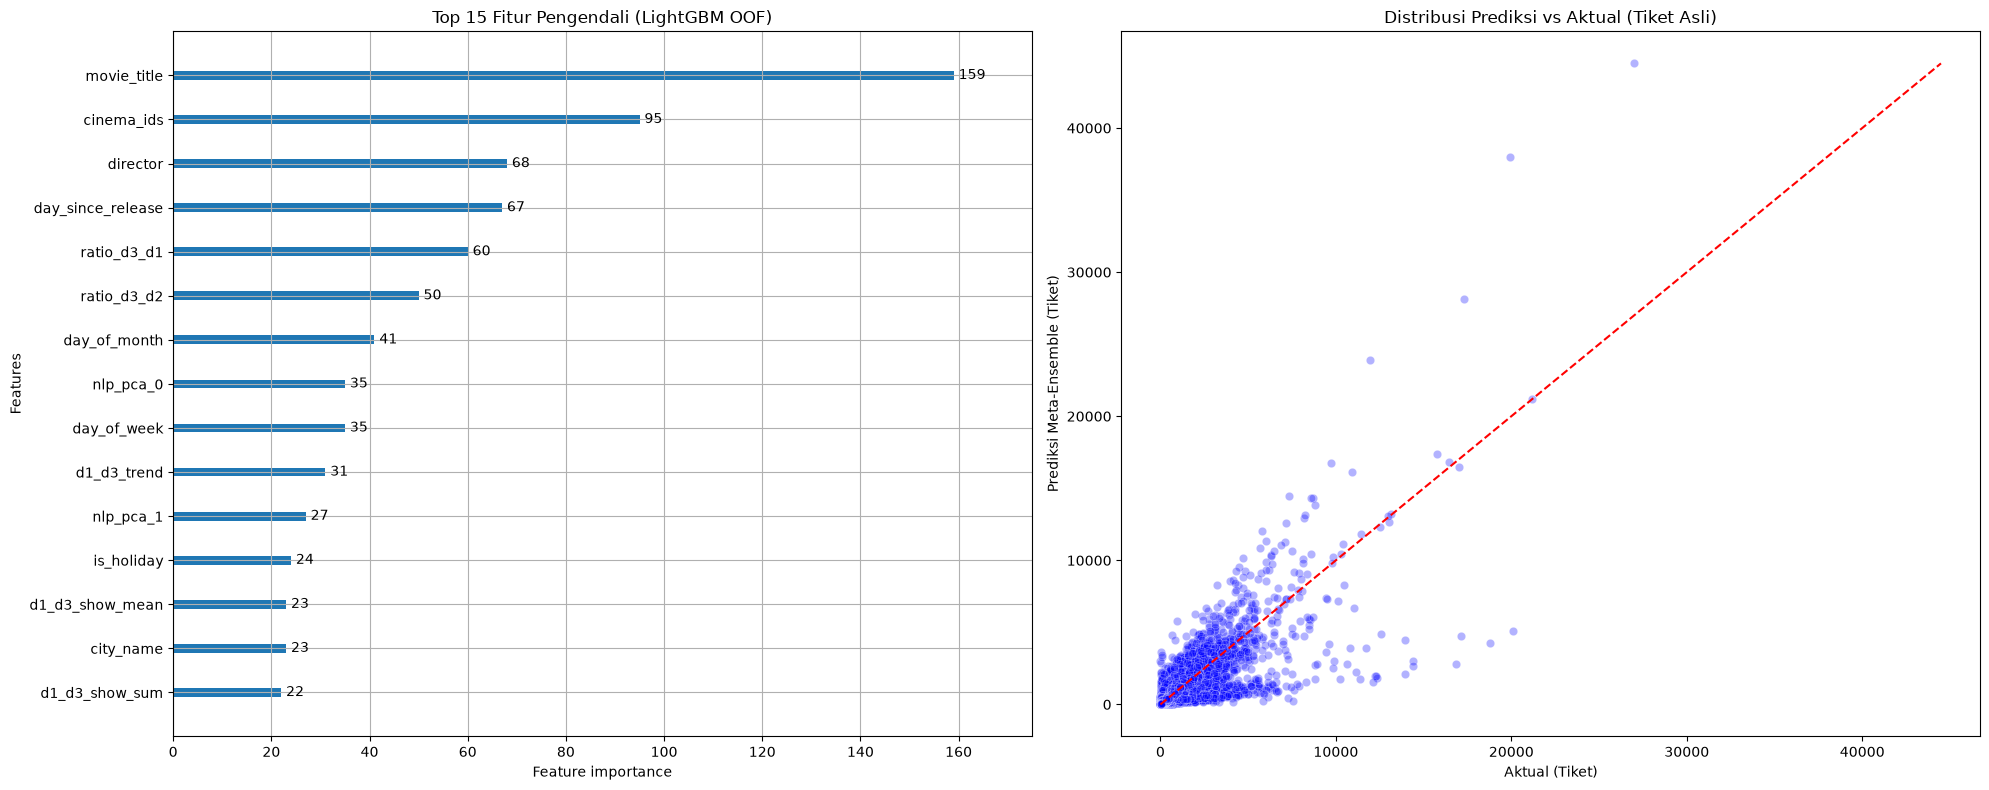

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error

print('>> Melakukan Evaluasi Kritis (M8)...')

# A. Keamanan State Memory
try:
    final_oof_scaled
except NameError:
    raise NameError("FATAL: Matriks Prediksi M7 tidak ditemukan di memori! Silakan run sel M7 terlebih dahulu.")

# B. Inverse Scaling ke Tiket Asli
# Membalikkan perhitungan y_scaled * Sp
final_pred_ticket = np.round(final_oof_scaled * sp_train).astype(int)

# C. Simulasi MASE dan MAE Asli
raw_mae = mean_absolute_error(y_train_raw, final_pred_ticket)
scaled_mae = mean_absolute_error(y_train_scaled, final_oof_scaled)

print('\n' + '='*50)
print('🎯 RAPOR KECERDASAN META-ENSEMBLE (M7)')
print('='*50)
print(f'[SKOR LOKAL] L1 Loss pada y_scaled (Simulasi MASE) : {scaled_mae:.5f}')
print(f'[SKOR LOKAL] Mean Absolute Error (Tiket Asli)      : {raw_mae:.2f} Tiket Melenceng')
print('='*50)

if scaled_mae < 0.40:
    print('🔥 LUAR BIASA! Target MASE Lokal menembus batas < 0.40! Ekstremamente Kuat!')
else:
    print('⚠️ Target cukup bagus, namun masih di atas batas psikologis 0.40.')

# D. Feature Importance & Residual Analytics
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. Feature Importance (diambil dari otak LightGBM lipatan terakhir M7)
lgb.plot_importance(model_lgb, max_num_features=15, ax=axes[0], title='Top 15 Fitur Pengendali (LightGBM OOF)')

# 2. Residual Scatter Plot
sns.scatterplot(x=y_train_raw, y=final_pred_ticket, alpha=0.3, ax=axes[1], color='blue')
# Garis diagonal ideal
max_val = max(y_train_raw.max(), final_pred_ticket.max())
axes[1].plot([0, max_val], [0, max_val], 'r--')
axes[1].set_title('Distribusi Prediksi vs Aktual (Tiket Asli)')
axes[1].set_xlabel('Aktual (Tiket)')
axes[1].set_ylabel('Prediksi Meta-Ensemble (Tiket)')

plt.tight_layout()
plt.show()


## 9. M9: Inferensi Data Uji Tertutup

Penerapan hukum fisika ke dalam matriks prediksi: Memotong probabilitas nilai minus dari tebakan algoritma Regresi, membulatkannya menjadi satuan bilangan asli, dan melakukan perhitungan invers silang menggunakan `Sp` khusus bioskop pengujian.

In [15]:
print('>> Memulai Inferensi Data Uji (M9)...')

# A. Keamanan State Memory
try:
    final_test_scaled
except NameError:
    raise NameError("FATAL: Prediksi Lapis 2 (final_test_scaled) tidak ditemukan! Harap run sel M7 terlebih dahulu.")

# B. Dekonstruksi Skala Target (Inverse Scaling)
print('Membalikkan skala (Inverse Scaling) prediksi uji menggunakan Sp historis...')
final_test_ticket = final_test_scaled * sp_test

# C. Pemurnian Hukum Fisika (Clipping & Rounding)
# Tiket tidak mungkin minus, dan tidak mungkin pecahan (orang tidak bisa dibagi 2)
final_test_ticket = np.clip(final_test_ticket, a_min=0, a_max=None)
final_test_ticket = np.round(final_test_ticket).astype(int)

# D. Uji Paritas Dimensi
if len(final_test_ticket) != len(test):
    raise ValueError(f"FATAL: Jumlah tebakan ({len(final_test_ticket)}) BERBEDA dengan baris test.csv ({len(test)})!")

print('\n✅ Inferensi Sukses! Data Uji telah diramalkan dan dibersihkan secara absolut.')
print(f'Total ramalan siap dikirim : {len(final_test_ticket)} baris')


>> Memulai Inferensi Data Uji (M9)...
Membalikkan skala (Inverse Scaling) prediksi uji menggunakan Sp historis...

✅ Inferensi Sukses! Data Uji telah diramalkan dan dibersihkan secara absolut.
Total ramalan siap dikirim : 72611 baris


## Evaluasi Tambahan (Extended Metrics)

Sebagai bentuk inspeksi mutlak atas akurasi *Meta-Ensemble*, kita mencetak seluruh dimensi matriks kesalahan: **MAE** (selisih tiket absolut), **RMSE** (penalti tinggi bagi tebakan yang melenceng jauh), dan **RMSLE** (rasio logaritmik, metrik yang paling stabil untuk nilai yang sangat besar/kecil).

In [16]:
from sklearn.metrics import mean_squared_error, r2_score

print('>> Menghitung Metrik Evaluasi Ekstrem (M8.5)...')

# A. Pastikan Variabel Tersedia
try:
    final_pred_ticket
    y_train_raw
except NameError:
    raise NameError("FATAL: Prediksi (final_pred_ticket) atau Target (y_train_raw) tidak ditemukan!")

# B. Perhitungan Metrik Matematika
calc_mae = mean_absolute_error(y_train_raw, final_pred_ticket)
calc_rmse = np.sqrt(mean_squared_error(y_train_raw, final_pred_ticket))

# Menghitung RMSLE (Root Mean Squared Logarithmic Error)
# Menggunakan log1p (log(1+x)) untuk mencegah error jika ada nilai 0
log_actual = np.log1p(y_train_raw)
log_pred = np.log1p(final_pred_ticket)
calc_rmsle = np.sqrt(mean_squared_error(log_actual, log_pred))

calc_r2 = r2_score(y_train_raw, final_pred_ticket)

# C. Mencetak Papan Rapor
print('\n' + '='*55)
print('📊 LAPORAN EVALUASI META-ENSEMBLE KOMPREHENSIF')
print('='*55)
print(f'➤ Mean Absolute Error (MAE)         : {calc_mae:.4f} tiket')
print(f'➤ Root Mean Squared Error (RMSE)    : {calc_rmse:.4f} tiket')
print(f'➤ RMS Logarithmic Error (RMSLE)     : {calc_rmsle:.4f}')
print(f'➤ Koefisien Determinasi (R2 Score)  : {calc_r2:.4f}')
print('='*55)


>> Menghitung Metrik Evaluasi Ekstrem (M8.5)...

📊 LAPORAN EVALUASI META-ENSEMBLE KOMPREHENSIF
➤ Mean Absolute Error (MAE)         : 196.4754 tiket
➤ Root Mean Squared Error (RMSE)    : 500.0036 tiket
➤ RMS Logarithmic Error (RMSLE)     : 0.8296
➤ Koefisien Determinasi (R2 Score)  : 0.5745


## 10. M10: Submission Generation

Garis *finish*. Merajut tebakan tiket bulat kita dengan pilar `id` resmi dari panitia, membuang baris indeks palsu, dan mencetak berkas *CSV* pamungkas yang dijamin kebal dari kesalahan penguraian (*Parsing Error*) Kaggle.

In [17]:
import pandas as pd
import os

print('>> Mencetak Artefak Kemenangan (M10)...')

# A. Keamanan State Memory
try:
    test
    final_test_ticket
except NameError:
    raise NameError("FATAL: Variabel `test` atau `final_test_ticket` tidak ditemukan! Pastikan sel M1 dan M9 sudah di-run.")

# B. Pembentukan Arsitektur Pengiriman
df_sub = pd.DataFrame({
    'id': test['id'],
    'total_ticket': final_test_ticket
})

# C. Protokol Pembersihan Visual (Data Casting Ekstrem)
# Memastikan tidak ada wujud pecahan desimal (float) yang menyusup sama sekali
df_sub['total_ticket'] = df_sub['total_ticket'].astype(int)

# D. Pengecoran Artefak (CSV Export)
submission_filename = 'submission_exp03.csv'
df_sub.to_csv(submission_filename, index=False)

print('\n✅ BINGO! Proses penempaan selesai.')
print(f'Berkas [{submission_filename}] telah berhasil dicetak secara permanen.')
print('Siap untuk diseret (Drag & Drop) ke Kaggle Competition!')
print('\n--- Inspeksi Visual (Sanity Check) 10 Baris Pertama ---')
display(df_sub.head(10))


>> Mencetak Artefak Kemenangan (M10)...

✅ BINGO! Proses penempaan selesai.
Berkas [submission_exp03.csv] telah berhasil dicetak secara permanen.
Siap untuk diseret (Drag & Drop) ke Kaggle Competition!

--- Inspeksi Visual (Sanity Check) 10 Baris Pertama ---


,id,total_ticket
0,1,58
1,2,50
2,3,43
3,4,40
4,5,36
5,6,74
6,7,70
7,8,143
8,9,124
9,10,103
